# 01｜位置だけの単体分割

画素中心 `(x+0.5, y+0.5)` に尺度を掛けて2次元格子へ配置します。色は分割に使いません。
包含単体の頂点集合をIDにするため、領域は三角形状になります。これはSLICではありません。

通常は `uv sync --all-groups` の後、プロジェクト環境のカーネルで実行します。
配布時の実行記録は `reports/notebooks/` にあります。接続方式は最初の出力に明記します。

In [1]:
import os

# 検証実行時だけ明示的に選ぶ接続です。通常実行はnanobindを使います。
if os.environ.get("PERMUTOHEDRAL_TEST_BRIDGE") == "1":
    from scripts._project import activate_test_bridge
    activate_test_bridge()

import numpy as np
from PIL import Image
from IPython.display import display
from permutohedral_segmentation import LatticeConfig, MergeConfig, segment
from permutohedral_segmentation import _native
from permutohedral_segmentation.datasets import load_example
from permutohedral_segmentation.visualization import render_labels, overlay_boundaries

backend = getattr(_native, "__test_backend__", "nanobind")
print("実行した接続方式:", backend)


実行した接続方式: ctypes-test-adapter (nanobind not validated)


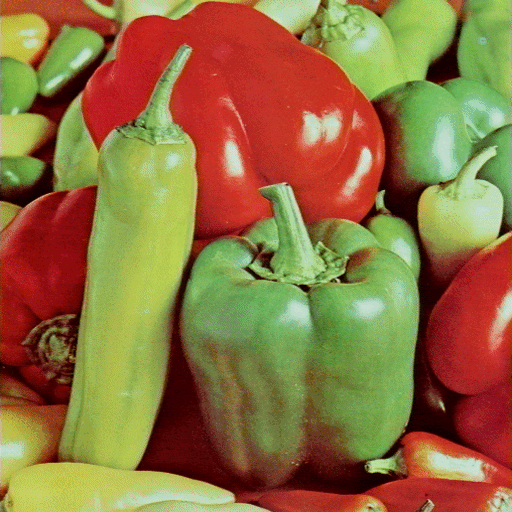

画像寸法: (512, 512, 3)


In [2]:
image = load_example("peppers")
display(Image.fromarray(image))
print("画像寸法:", image.shape)

尺度=0.05: 単体ID=1,590、連結成分=1,590


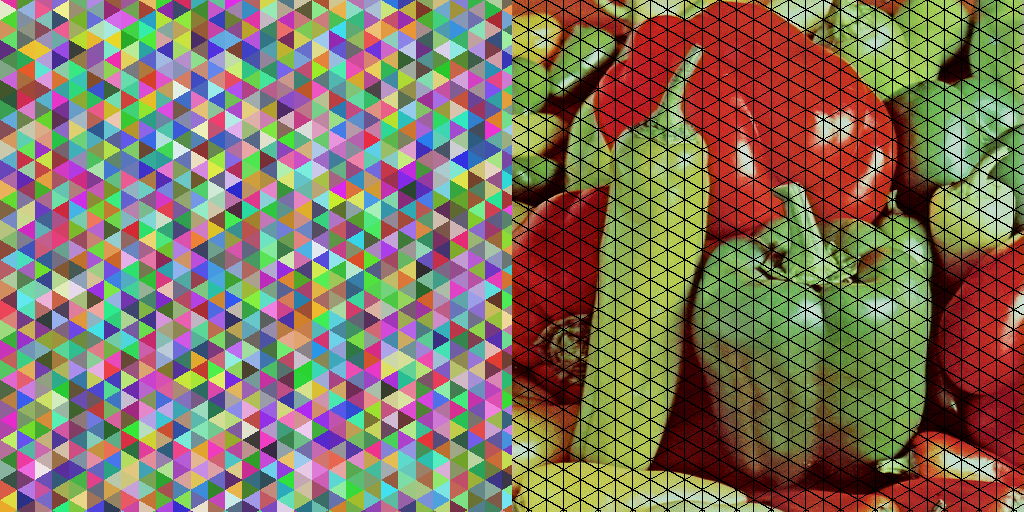

尺度=0.025: 単体ID=405、連結成分=405


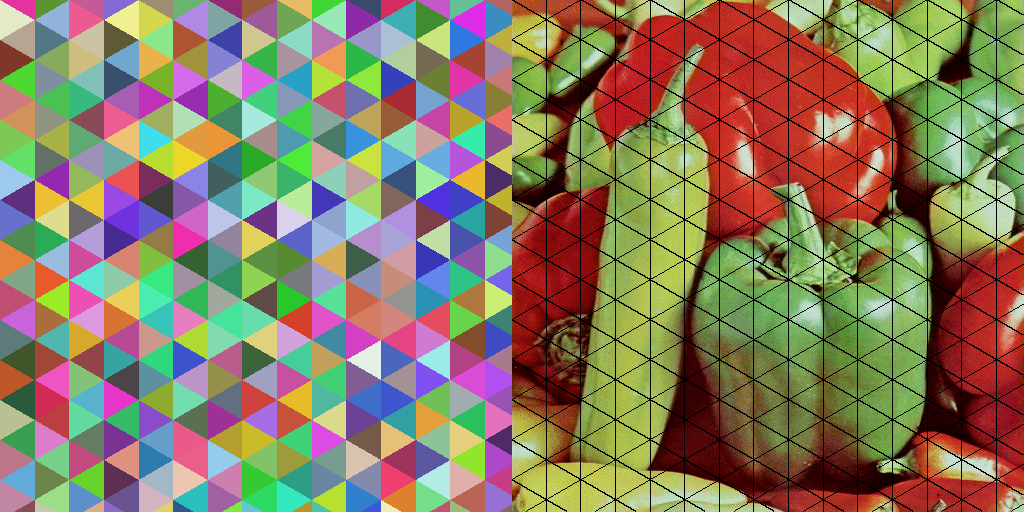

尺度=0.01: 単体ID=72、連結成分=72


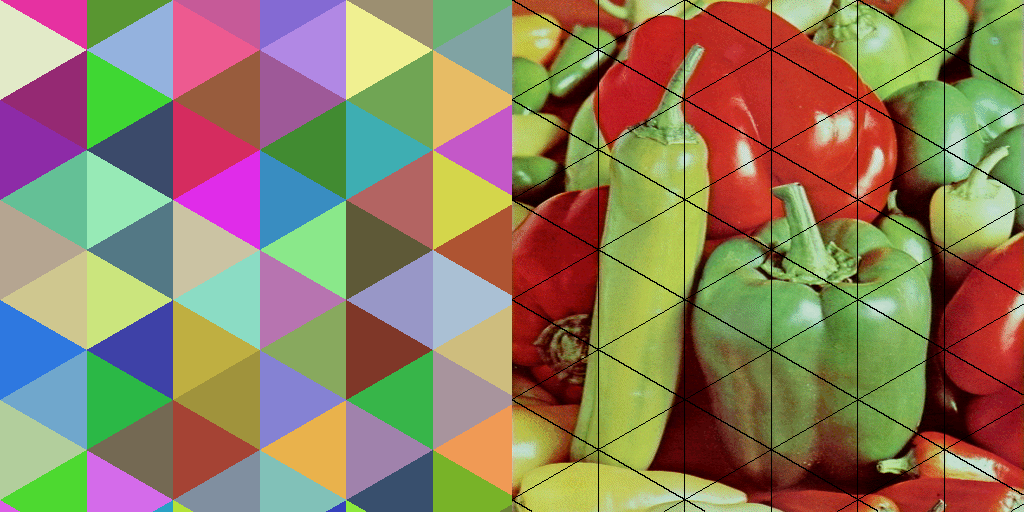

In [3]:
results = {}
for scale in (0.05, 0.025, 0.01):
    result = segment(image, lattice=LatticeConfig(mode="xy", spatial_scale=scale))
    results[scale] = result
    print(f"尺度={scale}: 単体ID={result.simplex_count:,}、連結成分={result.component_count:,}")
    display(Image.fromarray(np.concatenate([
        render_labels(result.labels), overlay_boundaries(image, result.labels)
    ], axis=1)))

## 不変条件の確認
寸法と位置尺度が同じなら、画像のRGB値が変わっても領域分割は変わりません。
以下の領域数は本プロジェクト同梱画像・同じ座標規約に対する回帰確認です。

In [4]:
assert {scale: result.region_count for scale, result in results.items()} == {
    0.05: 1590, 0.025: 405, 0.01: 72
}
changed = segment(255-image, lattice=LatticeConfig("xy", 0.025, 0.01))
np.testing.assert_array_equal(changed.labels, results[0.025].labels)
print("位置分割の不変条件: 合格")

位置分割の不変条件: 合格
